# Lab 1.8 · Image generation model architecture

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Why separate text conditioning, denoising, and decoding?

In a text-conditioned latent pipeline, a **text encoder** represents the prompt, a **denoiser** uses that representation while updating a noisy latent grid, and an **image decoder** converts the final latent into pixels. A latent is an internal representation. The image decoder, often the decoder side of a variational autoencoder (VAE), maps that representation back to pixels. Running repeated model evaluations on a smaller spatial grid can reduce work, although actual cost also depends on channels and architecture.

The notebook uses a prompt lookup instead of a text encoder, one supplied conditional update, and nearest-neighbor expansion instead of a learned decoder. For example, expanding the row [0.2, 0.8] by a factor of two gives [0.2, 0.2, 0.8, 0.8]. Repeat rows too, so a 2 × 2 latent becomes 4 × 4. Keep the starting latent fixed to isolate the effect of changing the prompt.

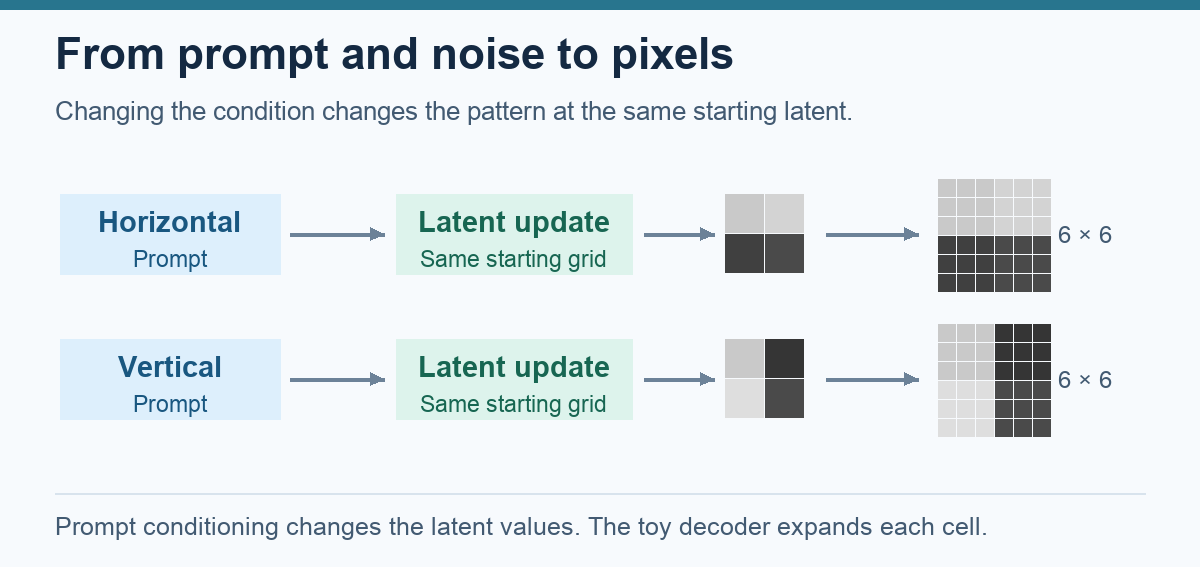

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Connect conditioning | Look up the prompt and pass it to one latent update. | The latent shape stays fixed while its values change. |
| 2. Decode to pixels | Expand each latent cell and compare two prompts. | The output shape grows and the prompt changes the pattern. |

In [ ]:
patterns = {
    "horizontal": [[1.0, 1.0], [0.0, 0.0]],
    "vertical": [[1.0, 0.0], [1.0, 0.0]],
}
initial = [[0.2, 0.4], [0.6, 0.8]]

def conditional_update(latent, condition):
    return [[0.25 * x + 0.75 * c for x, c in zip(row, cond_row)]
            for row, cond_row in zip(latent, condition)]

def show(image):
    return "\n".join("".join("#" if value >= 0.5 else "." for value in row)
                     for row in image)

## Exercise 1. Connect prompt conditioning

Look up the prompt's condition and pass it to the supplied update. Both prompts use the same initial latent. Predict which positions become brighter for each.

In [ ]:
def conditioned_latent(latent, prompt):
    return None

In [ ]:
horizontal = conditioned_latent(initial, "horizontal")
vertical = conditioned_latent(initial, "vertical")
if horizontal is not None:
    assert horizontal[0][1] > vertical[0][1]
    assert horizontal[1][0] < vertical[1][0]
    assert [len(row) for row in horizontal] == [2, 2]
    print("PASS — different conditions, same latent shape:", horizontal, vertical)

### Read the result

Compare cells that differ between prompt conditions. Both runs should preserve the latent shape.

## Exercise 2. Decode a latent grid

Repeat each value factor times across its row, and repeat each expanded row factor times down the image. Use independent output rows. Then run both prompts with factor 3 and compare the results.

In [ ]:
def decode(latent, factor):
    return None

In [ ]:
check_passed = False
probe = decode([[1, 2]], 2)
if probe is not None:
    assert probe == [[1, 1, 2, 2], [1, 1, 2, 2]]
    assert probe[0] is not probe[1]
    if horizontal is not None:
        a, b = decode(horizontal, 3), decode(vertical, 3)
        assert len(a) == 6 and all(len(row) == 6 for row in a)
        assert show(a).splitlines() == ["######"] * 3 + ["......"] * 3
        assert show(b).splitlines() == ["###..."] * 6
        print("Horizontal prompt\n" + show(a))
        print("Vertical prompt\n" + show(b))
        print("PASS — the prompts produce different images from the same initial state")
        check_passed = True
if not check_passed:
    print("Complete conditioned_latent and decode and rerun the checks in order.")

### Read the result

Expansion makes the grid larger. The pattern difference comes from conditioning before the decoder.

## Compare your results

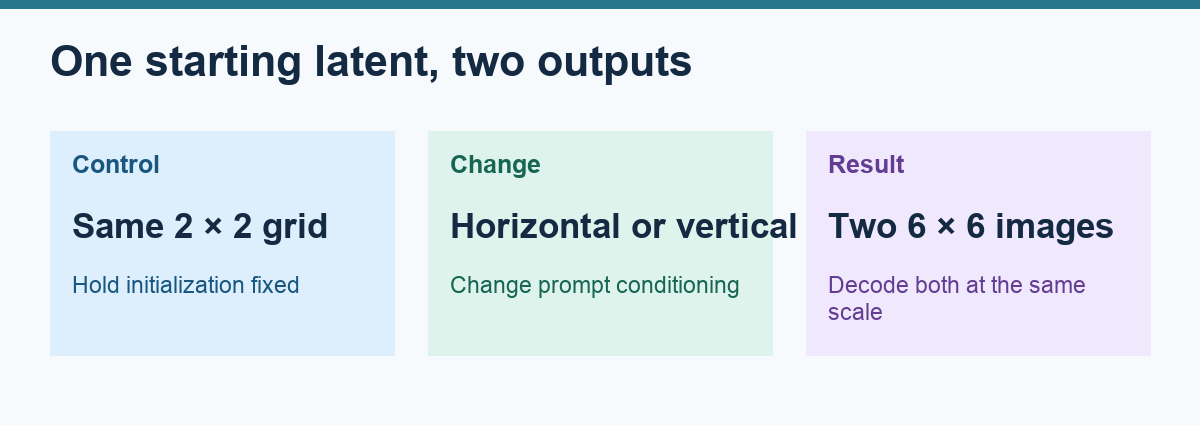

## Optional extension · Patches and a refinement stage

The book uses **SDXL** to illustrate how a pipeline can have a base denoiser and a refiner before the VAE decodes the result. The base establishes the image, while the refiner can improve details. Its comparison with Qwen Image also shows why replacing one pipeline component, such as the text encoder, can change the cost of serving the model.

A diffusion transformer can group regions of the latent grid into **patch tokens**, so attention operates over a sequence of patches. Our prompt lookup and grid expansion model the component interfaces. They approximate neither the learned VAE nor the denoiser's internal attention. The exercise below uses non-overlapping patches and a single full attention operation to isolate how token count grows with grid resolution.

Compare 4 × 4 and 8 × 8 latent grids using 2 × 2 patches. Count the tokens and the query-key pairs for full attention. Then trace where a refiner would fit between the lab's latent update and decoder. Which shape would it have to return to keep the decoder interface unchanged?

Predict the result before you run the cell.

**Reading** · Philip Kiely, *Inference Engineering*, §2.3.1, pp. 57–58.

In [ ]:
patch = 2
for side in (4, 8):
    tokens = (side // patch) ** 2
    print(f"{side} × {side}: {tokens} patch tokens, {tokens ** 2} attention pairs")
assert ((8 // patch) ** 2) ** 2 == 16 * (((4 // patch) ** 2) ** 2)

## Wrap-up

Decode the same latent with factors 2 and 4. What changes in pixel count? Which parts of a full generator would need to run again to change the prompt?

## Optional system exercise · Finding the repeated work in a pipeline

A trace reports 30 ms for text encoding, 12 ms per denoising step, and 30 ms for decoding. Estimate total time at 20 and 10 steps assuming no overlap and no other work. Where would a refiner factor into the accounting?